# 2. 分支结构

## 2.1 静态分支

### 2.1.1 并行节点

In [5]:
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import HumanMessage


from typing import TypedDict
from rich import print as rprint
from loguru import logger

from dotenv import load_dotenv
load_dotenv(override=True)


model = ChatOpenAI(
    model="gpt-3.5-turbo",
    base_url="https://api.closeai-asia.com/v1",  # closeai官方中转地址
    timeout=60
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    ci: str
    joke: str
    content_type: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(content=f"请写一首关于{state['topic']}的七言绝句。")]).content
    return {"poem": poem}

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(content=f"请写一个关于{state['topic']}的笑话。")]).content
    return {"joke": joke}

def node_c(state: OverAllState) -> OverAllState:
    ci = model.invoke([HumanMessage(content=f"请写一个关于{state['topic']}的词。")]).content
    return {"ci": ci}

def audit_node(state: OverAllState) -> OverAllState:
    logger.info(f"任务节点已经全部执行完毕，诗{'已生成' if state['poem'] else '未生成'}，笑话{'已生成' if state['joke'] else '未生成'}，词{'已生成' if state['ci'] else '未生成'}")
    return state


{
    'topic': '小猫',
    'poem': '软毛娇眼瞳，小猫撒娇嗓婉转。\n顽皮捉鱼虾，调皮逗众人开怀笑。',
    'joke': '为什么小猫不喜欢玩扑克牌？\n\n因为它总是抓不到一副好牌！'
}

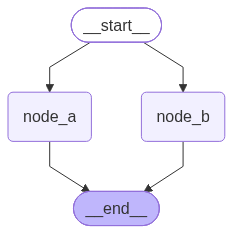

In [6]:
builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
result = graph.invoke({"topic": "小猫"})
rprint(result)

from IPython.display import display
display(graph)

上述案例中，`node_a` 和 `node_b` 都由 START 触发。图运行时，二者会在同一个超步中被调度，它们各自读取当前状态并独立执行。

需要注意的是：

- 这里的“并行”主要指调度语义上的并行；两个节点之间没有先后依赖；
- 它们的输出会在当前超步执行完成后统一合并到状态中；
- 如果两个节点写入同一个状态字段，则该字段通常需要配置合适的 `Reducer`，否则可能出现状态更新冲突，抛出 `InvalidUpdateError` 异常

### 2.1.2 条件分支

`StateGraph` 提供了 `add_conditional_edges` 方法，用于从某个上游节点出发，根据运行时状态选择下游节点。

方法签名如下：
```python
def add_conditional_edges(
    self,
    source: str,
    path: Callable[..., Hashable | Sequence[Hashable]]
    | Callable[..., Awaitable[Hashable | Sequence[Hashable]]]
    | Runnable[Any, Hashable | Sequence[Hashable]],
    path_map: dict[Hashable, str] | list[str] | None = None,
) -> Self:
    ...
```
不考虑 self，核心参数有三个：
- `source`：条件分支的起始节点；
- `path`：路由规则，是一个可执行对象，通常是函数
- `path_map`：路由规则的返回值到真实节点名之间的映射关系。

其中，`path` 的返回值表示跳转的目标节点，可以是：
- 字符串或特殊对象 `END` 表示的单个目标；
- 字符串或特殊对象 `END` 表示的多个目标组成的序列；

`path_map`
- 可以省略，即取默认值 None，此时 path 返回值中出现的字符串必须是合法的节点名称。
- 可以是字典，维护 path 返回值和真实节点的映射。
- 也可以是列表，如下
```python
path_map=["node_a", "node_b", "node_c"]
# 相当于
path_map={
    "node_a": "node_a",
    "node_b": "node_b",
    "node_c": "node_c",
}
```
此时也要求 path 返回值中出现的字符串必须是合法的节点名称。

{'topic': '小猫', 'joke': '为什么小猫总是喜欢打盹？\n\n因为它们总是要“猫”不住觉的！哈哈哈～', 'content_type': ''}

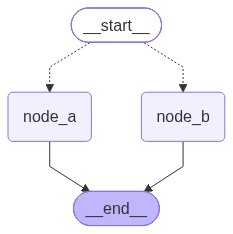

In [7]:
from typing import Literal


def route(state: OverAllState) -> Literal["node_a", "node_b"]:
    if "诗" in state["content_type"]:
        return "node_a"
    else:
        return "node_b"


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)

builder.add_conditional_edges(
    source=START,
    path=route
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
result = graph.invoke({"topic": "小猫", "content_type": ""})
# result = graph.invoke({"topic": "小猫", "content_type": "诗"})
rprint(result)

from IPython.display import display
display(graph)

{'topic': '小猫', 'joke': '为什么小猫喜欢在地上滚来滚去呢？\n\n因为它想当一只“滚猫”星！😹', 'content_type': ''}

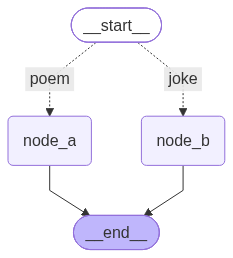

In [8]:
def route(state: OverAllState) -> Literal["node_a", "node_b"]:
    if "诗" in state["content_type"]:
        return "poem"
    else:
        return "joke"


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)

builder.add_conditional_edges(
    source=START,
    path=route,
    path_map={"poem": "node_a", "joke": "node_b"}
)

builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
result = graph.invoke({"topic": "小猫", "content_type": ""})
# result = graph.invoke({"topic": "小猫", "content_type": "诗"})
rprint(result)

from IPython.display import display
display(graph)

同时路由至多个节点

`add_conditional_edges`也支持一次路由到多个节点

{
    'topic': '小猫',
    'ci': 
'小猫，毛茸茸的小家伙，眼睛明亮、毛色各异，总是调皮可爱。它们会用灵巧的爪子捉住玩具，会用软绵绵的身体蹭蹭主人的腿，
会用温暖的身体取暖自己。小猫在主人面前撒娇、抓耙子，在外面独自玩耍捕鸟、爬树。小猫，是人们心中的伙伴，是家庭的一部
分，是生活的点缀。',
    'joke': '为什么小猫喜欢躺在电脑键盘上？\n因为它喜欢按键！',
    'content_type': ''
}

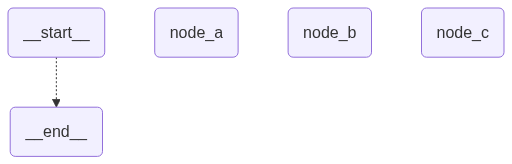

In [9]:
from typing import Sequence


def route(state: OverAllState) -> Sequence[Literal["node_a", "node_b", "node_c"]]:
    if "诗" in state["content_type"]:
        return ["node_a", "node_c"]
    else:
        return ["node_b", "node_c"]


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)

builder.add_conditional_edges(
    source=START,
    path=route
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
result = graph.invoke({"topic": "小猫", "content_type": ""})
# result = graph.invoke({"topic": "小猫", "content_type": "诗"})
rprint(result)

from IPython.display import display
display(graph)

{
    'topic': '小猫',
    'poem': '小猫捕鱼须有技，灵动身姿不停移。\n黑白相间眼如泉，萌态可爱撩人魂。',
    'ci': 
'小猫，那柔软的毛发，灵动的眼睛，宛如一团活泼的毛绒球。它们咬着骨头，抓着玩具，调皮地在家里来回跑来跑去。无论是懒洋
洋地晒太阳，还是嬉戏打闹，小猫总是给人带来无尽的快乐和笑容。它们懂得如何撒娇，如何寻找温暖的怀抱，如何用温柔的眼神
感动我们。小猫，是世界上最可爱的动物之一，如同一缕清风，一抹美丽的风景线，永远住在我们的心里。',
    'content_type': '诗'
}

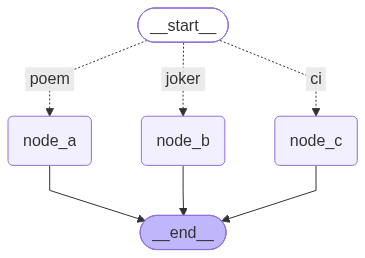

In [10]:
def route(state: OverAllState) -> Sequence[Literal["poem", "joker", "ci"]]:
    if "诗" in state["content_type"]:
        return ["poem", "ci"]
    else:
        return ["joker", "ci"]


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)

builder.add_conditional_edges(
    source=START,
    path=route,
    path_map={"poem": "node_a", "joker": "node_b", "ci": "node_c"}
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
# result = graph.invoke({"topic": "小猫", "content_type": ""})
result = graph.invoke({"topic": "小猫", "content_type": "诗"})
rprint(result)

from IPython.display import display
display(graph)

{
    'topic': '小猫',
    'poem': '软毛娇小猫，欢快跳跃躲藏毛。  \n红舌舔爪静，圆眼盯鱼咬。  \n嬉戏捉蝴蝶，纯真可爱到。  
\n家中猫咪乐，主人笑开颜。',
    'ci': 
'小猫，软软的毛发，灵动的眼睛，调皮的尾巴，总是在家中四处蹦跳。它用爪子抓我的腿，用嘴巴咬我的手，却总能让我开心笑。
它不怕生，喜欢趴在我怀里，享受着我的温暖和呵护。每当我感到孤独时，小猫总是在我身边，用它那温柔的表情和撒娇的动作，
让我感到无比温馨和幸福。小猫，是我生活中最珍贵的伴侣，它用无声的陪伴，填满了我的心灵空间。',
    'content_type': '诗'
}

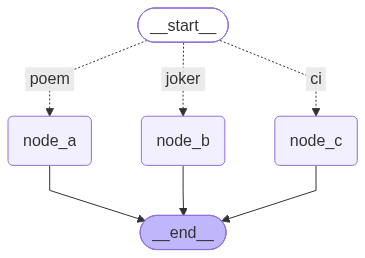

In [11]:
def route(state: OverAllState) -> Sequence[Literal["poem", "joker", "ci"]]:
    if "诗" in state["content_type"]:
        return ["poem", "ci"]
    else:
        return ["joker", "ci"]


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)

builder.add_conditional_edges(
    source=START,
    path=route,
    path_map={"poem": "node_a", "joker": "node_b", "ci": "node_c"}
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
# result = graph.invoke({"topic": "小猫", "content_type": ""})
result = graph.invoke({"topic": "小猫", "content_type": "诗"})
rprint(result)

from IPython.display import display
display(graph)

### 2.1.3 defer node execution

某些情况下，我们希望在所有常规任务节点执行完毕后，再进行日志、审计等收尾工作

此时可以在添加节点时设置`defer=True`，如下：
```python
builder.add_node("audit_node", audit_node, defer=True)
```

`defer=True` 的含义是：

当前节点不会在其被触发后立即执行，而是被延迟到常规图运行流程结束后，再在额外的超步中触发执行。

这类节点适合用于：

- 日志记录；
- 审计检查；
- 结果汇总；
- 收尾清理；
- 统一校验前面节点是否已完成。

**底层原理**

1. 编译阶段：使用特殊 Channel
    - LangGraph 在编译状态图时，会为边创建对应的 `Channel`。

    - 此时会根据节点的 defer 属性创建不同类型的 Channel，如下。
    ```python
   self.channels[branch_channel] = (
       LastValueAfterFinish(Any)
       if node.defer
       else EphemeralValue(Any, guard=False)
   )
    ```
    `defer` 默认值为 `False`

    对于普通节点，边对应的通道类型是 `EphemeralValue`，可以理解为普通临时通道；而对于 `defer=True` 的节点，边对应的通道类型是特殊的 `LastValueAfterFinish`。

2. 常规运行阶段-写入但不触发
    - 在图运行过程中，每个节点执行完成后，会向其下游边对应的 `Channel` 写入数据。
    - 常规的 Channel 在运行开始后处于可用状态，被写入后记录在 `updated_channels` 列表中，从而在下一个超步中触发下游节点的执行。
    - 但是，`LastValueAfterFinish` 类型的通道起初是不可用的，首次被写入时不会添加到 `updated_channels` 列表中，下游节点自然不会被触发。
3. 常规流程结束后：调用`finish()`唤醒延迟节点
    - LangGraph 底层用 `trigger_to_nodes` 维护了 边的 `Channel` -> 节点 的映射，是一个字典。
    - 在每个超步结束后，运行时会根据 `updated_channels` 判断是否还有新的节点需要被触发。
    - 如果 `updated_channels` 和 `trigger_to_nodes` 的 key 没有交集，说明当前没有新的普通节点需要继续执行，常规运行流程已结束。
    - 此时，LangGraph 运行时会调用所有 `Channel` 的 `finish()` 方法。
    - 对于普通 `Channel` ，`finish()` 通常不会产生新的触发效果；但对于 LastValueAfterFinish 类型通道，首次调用 `finish()` 时，会将内部的 `finished` 标记设置为 `True`，并返回 `True`。
    - 一旦 `finished=True`，该通道的 `is_available()` 就会变为 True。
    - 于是，原本被延迟的通道会被加入 `updated_channels`，从而在额外的超步中触发对应的 `defer` 节点。
4. 总结
因此，`defer=True` 的运行机制可以概括为：

> 触发边的 `Channel` 为特殊类型，首次写入不触发；常规流程结束后，特殊通道 `finish()`；通道变为可用；从而触发延迟节点，后者在额外超步中执行。

2026-10-15 15:43:02.792 | INFO     | __main__:audit_node:40 - 任务节点已经全部执行完毕，诗已生成，笑话已生成，词已生成


{
    'topic': '小猫',
    'poem': '软毛如丝眼似泉，顽皮调皮爱撒娇。\n咪咪叫声悠扬入耳，捉虫逐鱼真乐趣。',
    'ci': 
'小猫，有着灵巧的身姿，毛茸茸的小脸蛋，眯着慧黄的眼睛，可爱极了。它们会用柔软的小爪，在主人的腿上蹭来蹭去，发出撒娇
的声音，讨人喜欢。小猫喜欢玩耍，在家里的各个角落里蹦跳着，追逐着无形的玩伴，让人忍俊不禁。无论是白色的小猫还是虎斑
的小猫，它们都有着独特的魅力，成为了家庭中不可或缺的一员。让我们一起来爱护这些可爱的小猫，给予它们温暖和关爱。',
    'joke': '为什么小猫喜欢在纸箱里玩耍？\n\n因为它们觉得自己像一个宝藏藏在里面，哈哈！'
}

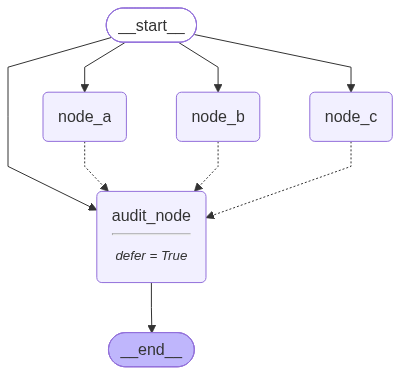

In [12]:
builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("audit_node", audit_node, defer=True)

builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge(START, "node_c")
builder.add_edge(START, "audit_node")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)
builder.add_edge("audit_node", END)

graph = builder.compile()
result = graph.invoke({"topic": "小猫"})
rprint(result)

from IPython.display import display
display(graph)

`defer=True` 适合“最后执行”的收尾节点。

它的本质是通过特殊的 `Channel` 控制触发时机：

- 编译阶段为延迟节点创建 `LastValueAfterFinish` 类型通道；
- 常规运行阶段该通道可以被写入，但不可用，不会触发下游节点；
- 常规流程结束后调用通道的 `finish()` 方法；
- `finish()` 首次生效后将通道标记为可用；
- 延迟节点在额外超步中被触发执行。

> 因此， `defer=True` 将节点的触发信号延迟释放，使该节点在常规流程结束后执行。

## 2.2 动态分支

- 定义：节点的后续执行路径在 **运行时** 才确定，可以根据当前状态、输入数据或中间结果，动态决定要触发哪些下游任务或跳转到哪个下游节点。

- 特点：

    - 下游执行目标可以在运行时选择；
    - 下游任务数量可以在运行时决定；
    - 可以为同一个下游节点动态创建多个执行任务；
    - 适合实现 `Map-Reduce` 式动态扇出、多任务并行处理、运行时条件跳转等场景。

    注意：需要注意的是，所谓“动态”通常不是指运行时临时创建新的节点定义。节点本身一般仍需要在图编译前注册。动态性主要体现在：运行时决定触发哪些节点，以及为这些节点创建多少个执行任务。

- 典型用法：

    - `Send`（动态扇出任务/数据）
    - `Command(goto=...)`（运行时跳转到下游节点）

    ⚡ 核心判断：
> 运行时决定后续执行目标或任务数量 → 动态分支

### 2.2.1 并行节点

`Send` 结合 `add_conditional_edges()` 使用，可以用于动态扇出任务

所谓`扇出（Fan-out）`，是指一个上游节点像扇子一样，向外分发出多个下游任务。例如，根据一个主题，同时生成诗、词、笑话三个任务；又如，根据一个列表，为列表中的每个元素动态启动一个处理任务。

具体来说，路由函数可以返回一个 `Send` 实例序列。每个 `Send` 实例都描述了一次独立的任务分发：

分发到哪个下游节点；
给这个下游节点传入什么私有状态。
运行时，LangGraph 会根据返回的每个 `Send` 实例创建对应的任务。这些任务通常会在同一个超步中并行执行。

`Send` 类构造器源码如下

```python
def __init__(self, /, node: str, arg: Any) -> None:
    """
    Initialize a new instance of the `Send` class.

    Args:
        node: The name of the target node to send the message to.
        arg: The state or message to send to the target node.
    """
    self.node = node
    self.arg = arg
```

该构造器接收两个参数，并记录为实例属性：

- `node`：待启动的下游节点名称，必须是已在状态图中注册的合法名称
- `arg`：传递给下游节点的信息，仅对`node`指向的节点可见，通常应是私有状态。每个 `Send` 实例接收到的 `arg` 是独立的，互不相干。


{
    'poem': 
'在青翠的草地上，\n一只小狗宛如飞驰的光。\n它用纯真的眼神，\n看着这个世界的美好。\n毛茸茸的身躯，\n洋溢着无尽的欢快
。\n它像一束温暖的阳光，\n照亮了我的心房。\n小狗啊，你是我的忠实伙伴，\n陪伴我度过每一个日夜。\n无论风雨还是晴天，\
n你都是我生活中最美丽的画面。',
    'ci': '1. 可爱的小狗\n2. 忠诚的小狗\n3. 活泼的小狗\n4. 萌萌的小狗\n5. 聪明的小狗\n6. 调皮的小狗\n7. 
快乐的小狗\n8. 伴随的小狗\n9. 眼睛大大的小狗\n10. 笑容灿烂的小狗',
    'joke': '为什么小狗总是喝水时都会弯着腰？因为它们怕水会流下去变成泥狗！😂'
}

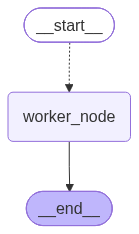

In [13]:
from langgraph.types import Send
from langgraph.graph import START, END, StateGraph
from langchain_openai import ChatOpenAI

from typing import TypedDict, Literal, Sequence
from rich import print as rprint
from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatOpenAI(
    model="gpt-3.5-turbo",
    base_url="https://api.closeai-asia.com/v1",  # closeai官方中转地址
    timeout=60
)


class OverAllState(TypedDict):
    topic: str
    poem: str
    ci: str
    joke: str


class WorkerState(TypedDict):
    content_type: Literal["poem", "joke", "ci"]
    prompt: str


class InputState(TypedDict):
    topic: str


class OutputState(TypedDict):
    poem: str
    ci: str
    joke: str


def worker_node(state: WorkerState) -> OutputState:
    content_type = state["content_type"]
    prompt = state["prompt"]
    content = model.invoke([HumanMessage(prompt)]).content
    return {content_type: content}


def router(state: InputState) -> Sequence[Send]:
    router_prompt = "请生成关于{}的{}"
    english2chinese = {
        "poem": "诗",
        "joke": "笑话",
        "ci": "词"
    }
    topic = state["topic"]
    return [Send(node="worker_node",
                 arg={
                     "content_type": content_type,
                     "prompt": router_prompt.format(topic, english2chinese[content_type])
                 })
            for content_type in english2chinese.keys()]


builder = StateGraph(state_schema=OverAllState, input_schema=InputState, output_schema=OutputState)
builder.add_node("worker_node", worker_node)
builder.add_conditional_edges(START, router, path_map=["worker_node"])
builder.add_edge("worker_node", END)

graph = builder.compile()
result = graph.invoke({"topic": "小狗"})
rprint(result)

from IPython.display import display

display(graph)

此处图结构能成功渲染的关键，是在 path_map 中显式声明了可能被路由到的下游节点：

```python
path_map=["worker_node"]
```

因为 `Send` 的目标和数量可以运行时动态决定，图渲染器无法仅靠运行时返回值提前知道图结构。通过 `path_map` 声明候选下游节点后，渲染图才能正确展示 `START` 到 `worker_node` 的条件边关系。

补充说明：如果多个并行任务写入同一个状态字段，通常需要为该字段定义 `reducer`，用于合并多个任务的输出。本例中三个任务分别写入 `poem`、`ci`、`joke` 三个不同字段，因此不会发生同一字段的并发合并问题。

### 2.2.2 条件分支

### 2.2.2.1 `Command`

`Command` 是 LangGraph 中用于控制图执行的多功能原语，它的构造器可以接受四个参数，并记录在同名类属性中：

- `update`：更新图状态，效果等同于节点直接返回状态更新字典；
- `goto`：指定节点执行完成后的跳转目标，可用于运行时条件分支。当需要同时更新状态并控制跳转时，比单独使用条件边更合适；
- `graph`：存在子图时，用于指定跳转发生在哪一层图中，例如从子图跳转到父图；
- `resume`：用于恢复被中断的图执行，常见于 `human-in-the-loop` 场景。


### 2.2.2.2 用`Command`实现条件分支

可以通过 `Command(goto=...)` 在节点内部实现条件分支。

与 `add_conditional_edges()` 相比，`Command` 更适合“状态更新”和“控制流跳转”需要放在同一个节点返回值中的场景。

例如，一个节点既要更新状态，又要根据当前状态决定下一步跳转目标，就可以返回：

```python
return Command(
    update={"foo": "bar"},
    goto="next_node"
)
```

============================== -> poem <- ==============================
{'topic': '布偶猫', 'content_type': 'poem', 'poem': '悠闲软绒身，眼中映清澈。\n优雅如波涌，温柔似微风。\n毛色精致美，身姿轻盈翔。\n温暖人心扉，是最爱的宠。', 'content_chinese': '一首诗歌'}
============================== -> joke <- ==============================
{'topic': '布偶猫', 'content_type': 'joke', 'joke': '为什么布偶猫总是笑得这么开心？\n\n因为它们知道，无论看起来多么天真无邪，其实他们是家里的真正老大！', 'content_chinese': '一则笑话'}
============================== -> illegal <- ==============================
{'topic': '布偶猫', 'content_type': 'illegal', 'content_chinese': '没有相关内容'}


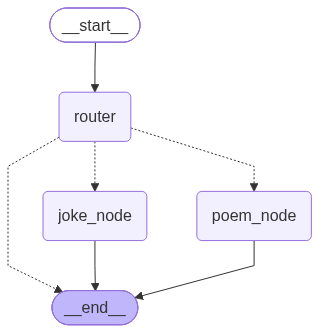

In [14]:
from langgraph.types import Command
from langgraph.graph import START, END, StateGraph
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI

from typing import TypedDict, Literal, Sequence

from rich import print as rprint
from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatOpenAI(
    model="gpt-3.5-turbo",
    base_url="https://api.closeai-asia.com/v1",  # closeai官方中转地址
    timeout=60
)


class OverAllState(TypedDict):
    topic: str
    content_type: Literal["poem", "joke"]
    poem: str
    joke: str
    content_chinese: str


def router(state: OverAllState) -> Command[Literal["poem_node", "joke_node", "__end__"]]:
    if state["content_type"] == "poem":
        return Command(goto="poem_node", update={"content_chinese": "一首诗歌"})
    elif state["content_type"] == "joke":
        return Command(goto="joke_node", update={"content_chinese": "一则笑话"})
    else:
        return Command(goto="__end__", update={"content_chinese": "没有相关内容"})


def poem_node(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(f"写一首关于{state['topic']}的诗")]).content
    return {"poem": poem}


def joke_node(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(f"写一个关于{state['topic']}的笑话")]).content
    return {"joke": joke}


# 构件图
builder = StateGraph(state_schema=OverAllState)
builder.add_node("router", router)
builder.add_node("joke_node", joke_node)
builder.add_node("poem_node", poem_node)

builder.add_edge(START, "router")
builder.add_edge("poem_node", END)
builder.add_edge("joke_node", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶猫", "content_type": "poem"})
joke_res = graph.invoke({"topic": "布偶猫", "content_type": "joke"})

# 这里故意传入一个不符合 Literal["poem", "joke"] 的值，
# 用来观察运行时兜底分支。
# 注意：Literal 主要服务于静态类型检查，
# 默认不会在 Python 运行时阻止非法值传入。
illegal_res = graph.invoke({
    "topic": "布偶猫",
    "content_type": "illegal"
})

print('=' * 30, '-> poem <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke <-', '=' * 30)
print(joke_res)
print('=' * 30, '-> illegal <-', '=' * 30)
print(illegal_res)

from IPython.display import display

display(graph)


这里使用：

`Command[Literal["poem_node", "joke_node", END]]`作为 `router()` 的返回值类型注解。

注解不能限制 `goto` 在运行时只能写这些值，而是为了让 LangGraph 和类型检查工具知道：这个节点可能跳转到哪些目标。对于图结构渲染来说，这个注解非常重要。如果不声明，渲染出来的图可能无法正确表达 `router` 节点的潜在跳转关系。

需要注意的是，如果某个节点使用 `Command(goto=...)` 控制后续跳转，一般不要再给这个节点额外添加普通下游边。否则，普通边和 `Command` 指定的跳转都可能生效，导致多个下游节点被同时触发。

因此，本例中只添加：

```python
builder.add_edge(START, "router")
```
而不添加类似下面这样的边：

```python
builder.add_edge("router", "poem_node")
builder.add_edge("router", "joke_node")
```
因为 `router` 的后续跳转已经由 `Command(goto=...)` 决定。


### 2.2.3 小结

动态分支有两类典型应用场景：

| 场景 | 典型 API | 说明 |
| ----------- | ----------- | ----------- |
| 动态扇出 |	Send + add_conditional_edges()	| 运行时创建多个任务，常用于 Map-Reduce |
| 动态跳转 |	Command(goto=...)	| 节点内部根据状态决定跳转目标 |

二者的区别如下：

`Send` 更强调“一个节点动态分发多个任务实例”；
`Command(goto=...)` 更强调“当前节点执行完后动态跳转到哪个节点”。
`Send` 解决的是：**运行时要启动多少个任务实例**。 `Command(goto=...)` 解决的是：**当前节点执行完后要去哪里**。

不过，无论是 `Send` 还是 `Command(goto=...)`，目标节点通常都需要提前注册到图中。所谓“动态”，主要是运行时动态决定任务数量、任务输入或跳转路径，而不是运行时临时创建新的节点。